In [13]:
import pygplates
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/Users/Simon/GIT/GPlatesClassStruggle/')
from reconstruction_classes import *

from ptt.subduction_convergence import find_overriding_and_subducting_plates

polyline = pygplates.PolylineOnSphere([(-60,40),(-50,40),(-40,35), (-20,40)])





0.000304617419787 (35.0, 40.0) 0.174532925199
0.000614256449619 (39.43198847093019, 25.76135215596254) 0.185012193521
0.00119787602312 (50.019505693616495, 40.03384971631634) 0.356988682564


[-180, 180, -90, 90]

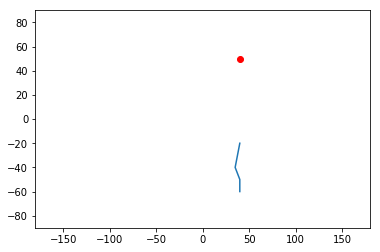

In [5]:
# cross product of normal and position of mid point

for i,segment in enumerate(polyline.get_segments()):
    
    
    normal = segment.get_great_circle_normal()
    
    segment_position_vector = segment.get_arc_point(0.5).to_xyz()
    
    segment_weight = segment.get_arc_length()
        
    stage_pole_position = pygplates.Vector3D.cross(normal,segment_position_vector)
    rotation_rate_vector = pygplates.Vector3D(stage_pole_position.to_xyz()) * np.radians(0.1)
    
    v = pygplates.Vector3D.cross(rotation_rate_vector, segment_position_vector)
    
    if i==0:
        weighting_factor = 0
        net_torque = pygplates.Vector3D(0, 0, 0)

    net_torque = net_torque + pygplates.Vector3D.cross(segment_position_vector, v) * segment_weight
    
    print net_torque.get_magnitude(), pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon(), segment_weight
    
plt.plot(polyline.to_lat_lon_array()[:,1],polyline.to_lat_lon_array()[:,0])
plt.plot(pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()[1],
         pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()[0],'ro')
plt.axis([-180,180,-90,90])


In [8]:
M2016 = ReconstructionModel('Matthews++2016')
M2016.add_rotation_model('/Users/simon/GIT/agegrid-dev/input_files/Rotations/Matthews_etal_GPC_2016_410-0Ma_GK07.rot')
M2016.add_static_polygons('/Users/simon/GIT/agegrid-dev/input_files/StaticPolygons/Muller_etal_AREPS_2016_StaticPolygons.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_MesozoicCenozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_Paleozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_TopologyBuildingBlocks.gpml')



(<pygplates.ResolvedTopologicalBoundary object at 0x1233bc7d0>, <pygplates.ResolvedTopologicalBoundary object at 0x123399320>, 'Left')
(<pygplates.ResolvedTopologicalBoundary object at 0x123399848>, <pygplates.ResolvedTopologicalBoundary object at 0x1233997d0>, 'Left')
(<pygplates.ResolvedTopologicalBoundary object at 0x1233998c0>, <pygplates.ResolvedTopologicalBoundary object at 0x123399848>, 'Left')
(<pygplates.ResolvedTopologicalBoundary object at 0x1233998c0>, <pygplates.ResolvedTopologicalBoundary object at 0x1233997d0>, 'Left')
(<pygplates.ResolvedTopologicalBoundary object at 0x1233997d0>, <pygplates.ResolvedTopologicalBoundary object at 0x123399848>, 'Left')
(<pygplates.ResolvedTopologicalBoundary object at 0x123399aa0>, <pygplates.ResolvedTopologicalBoundary object at 0x1233997d0>, 'Right')
(<pygplates.ResolvedTopologicalBoundary object at 0x123399c08>, <pygplates.ResolvedTopologicalBoundary object at 0x123399c80>, 'Right')
(<pygplates.ResolvedTopologicalBoundary object at 0x1

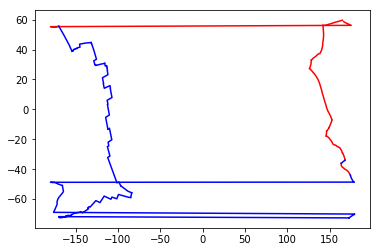

In [50]:
reconstruction_time = 50.

snapshot = M2016.plate_snapshot(reconstruction_time)

for topology in snapshot.resolved_topological_sections:
    
    shared_sub_segments = topology.get_shared_sub_segments()
    for shared_sub_segment in shared_sub_segments:
        if 901 in [resolved_topology.get_feature().get_reconstruction_plate_id() for resolved_topology in shared_sub_segment.get_sharing_resolved_topologies()]:
            #print shared_sub_segment.get_resolved_geometry().to_lat_lon_array()
            if shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_subduction_zone:
                print find_overriding_and_subducting_plates(shared_sub_segment,reconstruction_time)
                plt.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                         shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],'r')
            elif shared_sub_segment.get_resolved_feature().get_geometry() is not None:
                plt.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                         shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],'b')
                
                

